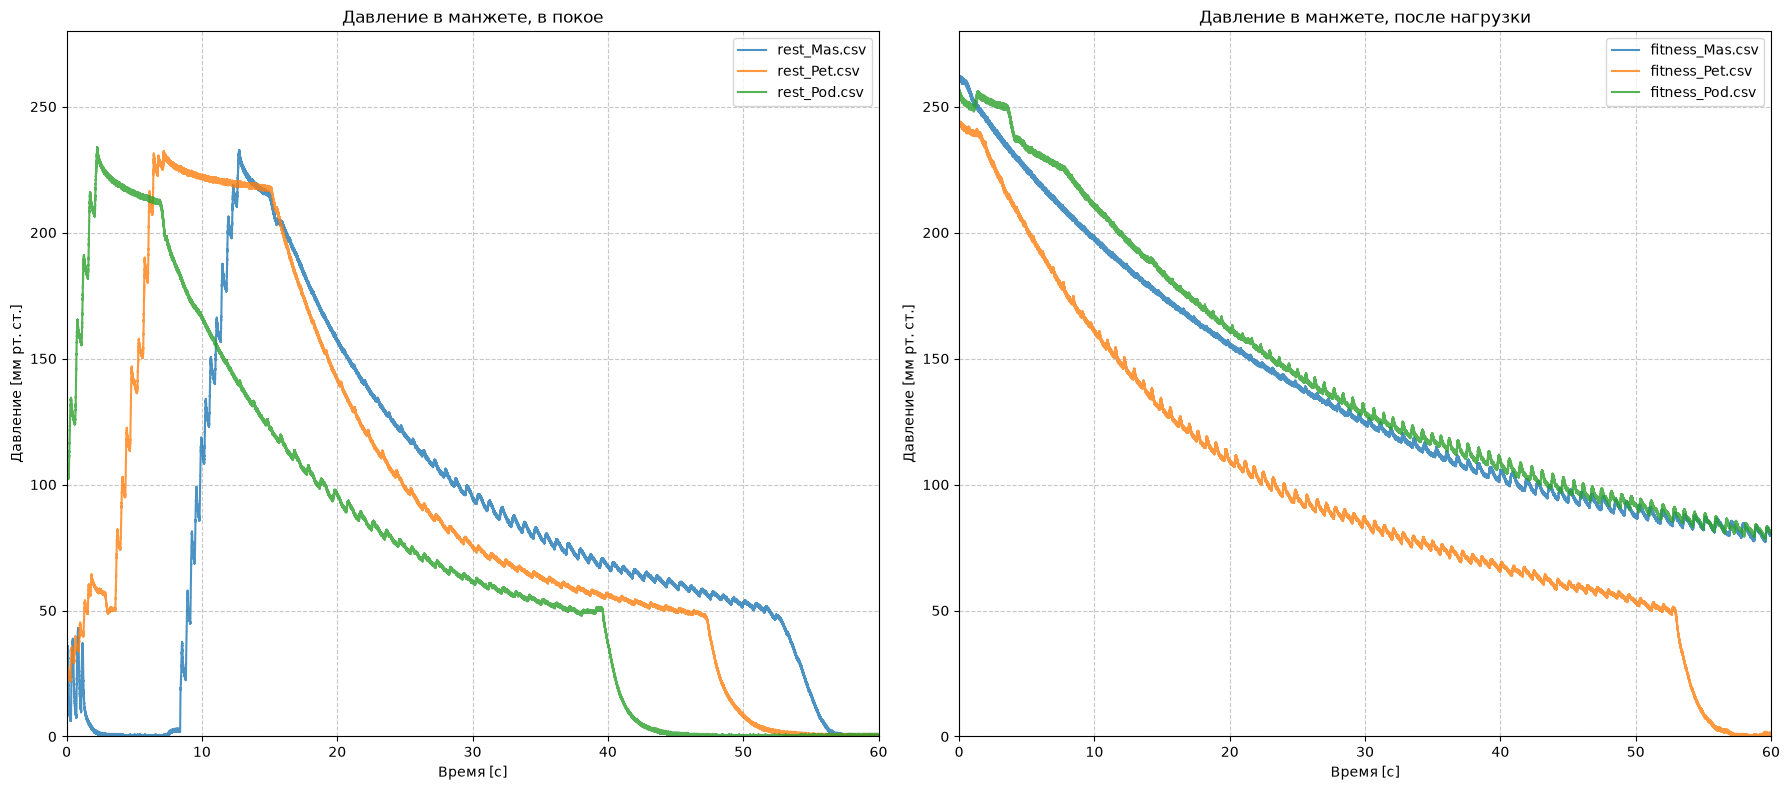

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

data_folder = '../5.3. Resting and post-exercise blood pressure'
files = ['rest_Mas.csv', 'rest_Pet.csv', 'rest_Pod.csv', 'fitness_Mas.csv', 'fitness_Pet.csv', 'fitness_Pod.csv']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

for f in files:
    filepath = os.path.join(data_folder, f)
    
    if not os.path.exists(filepath):
        continue
        
    df = pd.read_csv(filepath)
    t = df.iloc[:, 0].values
    p = df.iloc[:, 1].values

    if 'rest' in f:
        ax1.plot(t, p, label=f, alpha=0.8)
    elif 'fitness' in f:
        ax2.plot(t, p, label=f, alpha=0.8)

ax1.set_title('Давление в манжете, в покое')
ax1.set_xlabel('Время [с]')
ax1.set_ylabel('Давление [мм рт. ст.]')
ax1.set_xlim(0, 60)
ax1.set_ylim(0, 280)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.set_title('Давление в манжете, после нагрузки')
ax2.set_xlabel('Время [с]')
ax2.set_ylabel('Давление [мм рт. ст.]')
ax2.set_xlim(0, 60)
ax2.set_ylim(0, 280)
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('pressure_plots.png', bbox_inches='tight')
plt.show()

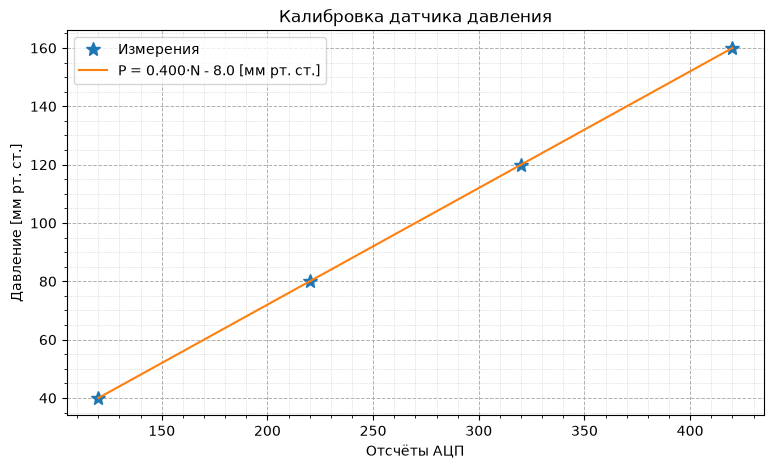

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# --- ДЛЯ ПРИМЕРА ---
# Допустим, ты прочитал файлы и получил средние значения в ВОЛЬТАХ:
# voltages = [0.60, 1.10, 1.60, 2.05] 

# 1. ОБЯЗАТЕЛЬНО переводим вольты в целые отсчёты АЦП!
# Если у тебя уже целые числа (например, 120, 220, 320, 420), то этот шаг пропускаешь.
N = np.array([120, 220, 320, 420])  # Здесь должны быть твои средние отсчёты
P = np.array([40, 80, 120, 160])    # Давление, мм рт. ст.

# 2. Строим прямую (линейная аппроксимация)
coeffs = np.polyfit(N, P, 1)
k = coeffs[0]
b = coeffs[1]

# Красиво форматируем уравнение для легенды (чтобы было + или -)
sign = "+" if b >= 0 else "-"
eq_text = f"P = {k:.3f}·N {sign} {abs(b):.1f} [мм рт. ст.]"

# 3. Рисуем график
plt.figure(figsize=(9, 5))

# Точки (синие звездочки)
plt.plot(N, P, '*', color='#1f77b4', markersize=10, label='Измерения')
# Линия тренда (оранжевая сплошная)
plt.plot(N, np.polyval(coeffs, N), '-', color='#ff7f0e', label=eq_text)

# 4. Оформление как в образце
plt.title("Калибровка датчика давления")
plt.xlabel("Отсчёты АЦП")
plt.ylabel("Давление [мм рт. ст.]")

# Включаем сетку (крупную и мелкую)
plt.grid(True, which='major', linestyle='--', linewidth=0.7)
plt.minorticks_on()
plt.grid(True, which='minor', linestyle=':', linewidth=0.5, alpha=0.7)

# Легенда в левом верхнем углу
plt.legend(loc='upper left')

plt.show()

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import find_peaks
from scipy.ndimage import median_filter, uniform_filter1d


# ==========================================
# НАСТРОЙКИ (ТВОИ ПУТИ НА МЕСТЕ)
# ==========================================

data_folder = '../5.3. Resting and post-exercise blood pressure'
plots_folder = 'plots'

os.makedirs(plots_folder, exist_ok=True)

files = [
    'rest_Mas.csv',
    'rest_Pet.csv',
    'rest_Pod.csv',
    'fitness_Mas.csv',
    'fitness_Pet.csv',
    'fitness_Pod.csv'
]

wave_start = {
    'rest_Mas.csv': None,
    'rest_Pet.csv': None,
    'rest_Pod.csv': None,
    'fitness_Mas.csv': None,
    'fitness_Pet.csv': None,
    'fitness_Pod.csv': None
}


# ==========================================
# ОБРАБОТКА ОДНОЙ ЗАПИСИ
# ==========================================

def process_record(filename):

    filepath = os.path.join(data_folder, filename)

    if not os.path.exists(filepath):
        print('Файл не найден:', filepath)
        return

    df = pd.read_csv(filepath)

    time = df.iloc[:, 0].to_numpy(dtype=float)
    p_raw = df.iloc[:, 1].to_numpy(dtype=float)

    # ======================================
    # ДОБАВЛЕНО: КАЛИБРОВКА (Перевод в мм рт. ст.)
    # ======================================
    # Внимание! Замени k и b на свои коэффициенты из пункта 5.4!
    k = 0.410 
    b = -10.9 
    
    # ЕСЛИ в твоих CSV файлах лежат ВОЛЬТЫ (например, 0.62), 
    # а не целые отсчёты (например, 127), раскомментируй строчку ниже:
    # p_raw = p_raw * 1023 / 5.0

    # Применяем формулу P = k*N + b
    p_raw = np.polyval([k, b], p_raw)
    # ======================================

    # Удаляем некорректные значения
    valid = np.isfinite(time) & np.isfinite(p_raw)
    time = time[valid]
    p_raw = p_raw[valid]

    # Сортировка по времени
    order = np.argsort(time)
    time = time[order]
    p_raw = p_raw[order]

    # Начало времени с нуля
    time = time - time[0]

    if len(time) < 100:
        print(filename, '- недостаточно данных')
        return

    duration = time[-1]
    rate = 1 / np.median(np.diff(time))

    # ======================================
    # 1. СГЛАЖИВАНИЕ ДАВЛЕНИЯ 50 мс
    # ======================================

    window = max(1, int(rate * 0.05))

    p = uniform_filter1d(
        p_raw,
        size=window,
        mode='nearest'
    )

    # Начало спуска давления
    max_idx = np.argmax(p)

    # ======================================
    # 2. ВЫЧИТАНИЕ ТРЕНДА 1.5 СЕКУНДЫ
    # ======================================

    window_trend = max(1, int(rate * 1.5))

    trend = uniform_filter1d(
        p,
        size=window_trend,
        mode='nearest'
    )

    osc = p - trend

    # ======================================
    # 3. ПОИСК ПИКОВ И ВПАДИН
    # ======================================

    distance = max(1, int(0.4 * rate))

    peaks, _ = find_peaks(
        osc[max_idx:],
        distance=distance,
        prominence=0.3
    )

    troughs, _ = find_peaks(
        -osc[max_idx:],
        distance=distance,
        prominence=0.3
    )

    peaks += max_idx
    troughs += max_idx

    # ======================================
    # 4. АМПЛИТУДА ПУЛЬСОВЫХ ВОЛН
    # ======================================

    amp = []
    amp_time = []
    amp_pressure = []

    for a, b in zip(troughs[:-1], troughs[1:]):

        if b <= a + 1:
            continue

        top = a + np.argmax(osc[a:b])

        amplitude = osc[top] - osc[a]

        amp.append(amplitude)
        amp_time.append(time[top])
        amp_pressure.append(p[top])

    amp = np.array(amp)
    amp_time = np.array(amp_time)
    amp_pressure = np.array(amp_pressure)

    if len(amp) < 8:
        print(filename, '- недостаточно пульсовых волн')
        return

    # ======================================
    # 5. МЕДИАННОЕ СГЛАЖИВАНИЕ ПО 7 ВОЛНАМ
    # ======================================

    amp_smooth = median_filter(
        amp,
        size=7,
        mode='nearest'
    )

    max_amp_idx = np.argmax(amp_smooth)
    max_amp = amp_smooth[max_amp_idx]

    # ======================================
    # 6. ОПРЕДЕЛЕНИЕ НАЧАЛА ПУЛЬСОВЫХ ВОЛН
    # ======================================

    manual_start = wave_start[filename]

    if manual_start is not None:

        start_idx = np.searchsorted(
            amp_time,
            manual_start
        )

    else:

        # Автоматический поиск начала устойчивых волн
        threshold = max(
            0.3,
            0.12 * max_amp
        )

        start_idx = 0

        for i in range(len(amp_smooth) - 2):

            if np.all(
                amp_smooth[i:i+3] > threshold
            ):
                start_idx = i
                break

    # ======================================
    # 7. СИСТОЛИЧЕСКОЕ ДАВЛЕНИЕ
    # ======================================

    # Пятая волна после появления пульсаций
    sys_idx = start_idx + 4

    if sys_idx >= len(amp):
        print(filename, '- невозможно определить систолу')
        return

    t_sys = amp_time[sys_idx]
    p_sys = amp_pressure[sys_idx]

    # ======================================
    # 8. ДИАСТОЛИЧЕСКОЕ ДАВЛЕНИЕ
    # ======================================

    dia_idx = None

    candidates = np.where(
        amp_smooth[max_amp_idx + 1:] < 0.8 * max_amp
    )[0]

    if len(candidates) > 0:

        dia_idx = (
            max_amp_idx + 1 + candidates[0]
        )

        t_dia = amp_time[dia_idx]
        p_dia = amp_pressure[dia_idx]

    # ======================================
    # 9. ПУЛЬС НА УЧАСТКЕ 10-30 СЕКУНД
    # ======================================

    inside = peaks[
        (time[peaks] > 10) &
        (time[peaks] < 30)
    ]

    if len(inside) >= 2:

        pulse = (
            (len(inside) - 1) * 60 /
            (time[inside[-1]] - time[inside[0]])
        )

    else:
        pulse = None

    # ======================================
    # 10. ВЫВОД РЕЗУЛЬТАТОВ
    # ======================================

    print('\n' + '-' * 40)
    print(filename)

    if pulse is not None:
        print(f'Пульс: {pulse:.0f} уд/мин')
    else:
        print('Пульс: недостаточно данных')

    print(f'Систолическое давление: {p_sys:.0f} мм рт. ст.')

    if dia_idx is not None:
        print(f'Диастолическое давление: {p_dia:.0f} мм рт. ст.')
        print(f'Давление: {p_sys:.0f}/{p_dia:.0f} мм рт. ст.')
    else:
        print('Диастолическое давление: не определено')

    if manual_start is None:
        print(
            f'Автоматическое начало волн: '
            f'{amp_time[start_idx]:.2f} с'
        )

    if np.max(p) > 200:
        print('ВНИМАНИЕ: давление выше 200 мм рт. ст.!')
        print('Проверь калибровку и исходные данные.')

    # ======================================
    # 11. ГРАФИК ДАВЛЕНИЯ
    # ======================================

    prefix = filename.replace('.csv', '')

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(
        time,
        p,
        color='blue',
        linewidth=1,
        label='Давление'
    )

    ax.plot(
        t_sys,
        p_sys,
        'r*',
        markersize=15,
        label=f'Систола: {p_sys:.0f}'
    )

    ax.annotate(
        'Систола',
        (t_sys, p_sys),
        xytext=(8, 10),
        textcoords='offset points'
    )

    if dia_idx is not None:

        ax.plot(
            t_dia,
            p_dia,
            'g*',
            markersize=15,
            label=f'Диастола: {p_dia:.0f}'
        )

        ax.annotate(
            'Диастола',
            (t_dia, p_dia),
            xytext=(8, 10),
            textcoords='offset points'
        )

    ax.set_title(f'Давление в манжете ({prefix})')
    ax.set_xlabel('Время, с')
    ax.set_ylabel('Давление, мм рт. ст.')

    # Нормальная шкала давления
    ax.set_ylim(
        0,
        max(180, np.ceil(np.max(p) / 20) * 20 + 10)
    )

    ax.set_xlim(0, duration)

    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            plots_folder,
            prefix + '-pressure.png'
        ),
        dpi=150
    )

    plt.close(fig)

    # ======================================
    # 12. ГРАФИК ПУЛЬСАЦИЙ
    # ======================================

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(
        time,
        osc,
        color='blue',
        linewidth=0.8,
        label='Пульсовые волны'
    )

    ax.plot(
        time[peaks],
        osc[peaks],
        'r.',
        markersize=5,
        label='Пики'
    )

    ax.set_title(f'Пульсации ({prefix})')
    ax.set_xlabel('Время, с')
    ax.set_ylabel('Пульсации, мм рт. ст.')

    ax.set_xlim(0, duration)

    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            plots_folder,
            prefix + '-pulse.png'
        ),
        dpi=150
    )

    plt.close(fig)

    # ======================================
    # 13. ГРАФИК АМПЛИТУДЫ
    # ======================================

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(
        amp_time,
        amp,
        'o',
        color='lightblue',
        label='Амплитуда волн'
    )

    ax.plot(
        amp_time,
        amp_smooth,
        color='blue',
        label='Медиана по 7 волнам'
    )

    ax.axhline(
        0.8 * max_amp,
        color='green',
        linestyle='--',
        label='80% максимума'
    )

    ax.plot(
        amp_time[sys_idx],
        amp_smooth[sys_idx],
        'r*',
        markersize=15,
        label='Систола'
    )

    if dia_idx is not None:

        ax.plot(
            amp_time[dia_idx],
            amp_smooth[dia_idx],
            'g*',
            markersize=15,
            label='Диастола'
        )

    ax.set_title(f'Амплитуда пульсовых волн ({prefix})')
    ax.set_xlabel('Время, с')
    ax.set_ylabel('Амплитуда, мм рт. ст.')

    ax.set_xlim(0, duration)

    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            plots_folder,
            prefix + '-amplitude.png'
        ),
        dpi=150
    )

    plt.close(fig)


# ==========================================
# ЗАПУСК ОБРАБОТКИ
# ==========================================

print('\nЗАПИСИ В ПОКОЕ')

for filename in files:
    if filename.startswith('rest'):
        process_record(filename)


print('\nЗАПИСИ ПОСЛЕ НАГРУЗКИ')

for filename in files:
    if filename.startswith('fitness'):
        process_record(filename)


print('\nОбработка завершена!')
print('Графики сохранены в папке:', plots_folder)


ЗАПИСИ В ПОКОЕ

----------------------------------------
rest_Mas.csv
Пульс: 49 уд/мин
Систолическое давление: 44 мм рт. ст.
Диастолическое давление: 18 мм рт. ст.
Давление: 44/18 мм рт. ст.
Автоматическое начало волн: 14.98 с

----------------------------------------
rest_Pet.csv
Пульс: 58 уд/мин
Систолическое давление: 52 мм рт. ст.
Диастолическое давление: не определено
Автоматическое начало волн: 15.12 с

----------------------------------------
rest_Pod.csv
Пульс: 61 уд/мин
Систолическое давление: 47 мм рт. ст.
Диастолическое давление: не определено
Автоматическое начало волн: 6.93 с

ЗАПИСИ ПОСЛЕ НАГРУЗКИ

----------------------------------------
fitness_Mas.csv
Пульс: 66 уд/мин
Систолическое давление: 63 мм рт. ст.
Диастолическое давление: не определено
Автоматическое начало волн: 2.08 с

----------------------------------------
fitness_Pet.csv
Пульс: 86 уд/мин
Систолическое давление: 73 мм рт. ст.
Диастолическое давление: 25 мм рт. ст.
Давление: 73/25 мм рт. ст.
Автоматическое